# Bước 3-5 (v2): Trích chọn đặc trưng, Huấn luyện mô hình, Đánh giá — **sau khi tích hợp dữ liệu Phase 2**
## Bài toán: Phát hiện Spam / Ham cho bình luận Facebook PTIT

Notebook này **giữ nguyên bố cục và phương pháp** của `spam-ham-comments.ipynb` (bản cũ), chỉ khác:

- **Dữ liệu:** `comments_labeled_merged.csv` = Phase 1 (31,931 bình luận cũ) + Phase 2 (bình luận mới crawl,
  gán nhãn bằng cùng quy trình GLM + Argilla). Cột `source` cho biết dòng thuộc `phase1` hay `phase2`.
- **Chia tập:** test set của Phase 1 được giữ **giống hệt bản cũ** (cùng `random_state`, cùng stratify),
  Phase 2 được chia 80/20 riêng rồi ghép vào → so sánh công bằng với kết quả cũ.
- **Mục 6 (mới):** so sánh *trước* (train chỉ Phase 1) và *sau* (train Phase 1 + 2) trên cùng test set.
- **Mục 7 (mới):** cải tiến nhẹ theo hướng phát triển trong báo cáo: `class_weight='balanced'` và tối ưu ngưỡng.

Các bước:
- **Bước 3 — Trích chọn đặc trưng**: Bag-of-Words (BoW), TF-IDF, Word Embeddings (Word2Vec).
- **Bước 4 — Xây dựng và huấn luyện mô hình**: Naive Bayes, SVM, trên từng loại đặc trưng.
- **Bước 5 — Đánh giá mô hình**: Accuracy, Precision, Recall, F1-Score, Confusion Matrix, và **biểu đồ so sánh**.

## 0. Cài đặt thư viện cần thiết

In [1]:
!pip install gensim underthesea scikit-learn pandas matplotlib huggingface_hub


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import hstack, csr_matrix

from underthesea import word_tokenize
from gensim.models import Word2Vec

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB, GaussianNB
from sklearn.svm import LinearSVC
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
POS_LABEL = "spam"   # nhãn được coi là lớp "dương" khi tính precision/recall/f1 nhị phân
import glob
import os

## 1. Tải dataset

Notebook tự tìm file `comments_labeled_merged.csv` theo thứ tự:
1. **Kaggle Input** (`/kaggle/input/...`) — nếu bạn upload file CSV thành Kaggle Dataset và *Add Input* vào notebook.
2. Thư mục `data/` (khi chạy local).
3. **Hugging Face Hub (gated)** qua Kaggle Secrets `HF_TOKEN` — giống notebook cũ
   (cần upload file `comments_labeled_merged.csv` lên repo dataset trước).

**Thiết lập secret trên Kaggle (nếu dùng cách 3):** *Add-ons → Secrets* → thêm `HF_TOKEN` → bật *Attached*.

In [3]:
DATA_FILENAME = "comments_labeled_merged.csv"
HF_REPO_ID = "p-storm/ptit-facebook-comments-spamham"

candidates = glob.glob(f"/kaggle/input/**/{DATA_FILENAME}", recursive=True) + glob.glob(f"data/{DATA_FILENAME}")

if candidates:
    csv_path = candidates[0]
else:
    from kaggle_secrets import UserSecretsClient
    from huggingface_hub import hf_hub_download

    HF_TOKEN = UserSecretsClient().get_secret("HF_TOKEN")
    csv_path = hf_hub_download(repo_id=HF_REPO_ID, filename=DATA_FILENAME, repo_type="dataset", token=HF_TOKEN)

print("Đọc dataset từ:", csv_path)

Đọc dataset từ: data/comments_labeled_merged.csv


## 1.1. Đọc dữ liệu đã gán nhãn

In [4]:
df = pd.read_csv(csv_path)

df = df[df["label"].isin(["spam", "ham"])].copy()
df = df.dropna(subset=["cleaned_text"]).reset_index(drop=True)
df["cleaned_text"] = df["cleaned_text"].astype(str)
if "source" not in df.columns:
    df["source"] = "phase1"

print(f"Tổng số bình luận: {len(df)}")
print(df["label"].value_counts())
print()
print("Phân bố nhãn theo nguồn dữ liệu:")
print(pd.crosstab(df["source"], df["label"], margins=True))
print()
print("Phân bố comment_type:")
print(df["comment_type"].value_counts() if "comment_type" in df.columns else "Không có cột comment_type")
df.head()

Tổng số bình luận: 38233
label
ham     33919
spam     4314
Name: count, dtype: int64

Phân bố nhãn theo nguồn dữ liệu:
label     ham  spam    All
source                    
phase1  28722  3209  31931
phase2   5197  1105   6302
All     33919  4314  38233

Phân bố comment_type:
comment_type
comment    23388
reply      14845
Name: count, dtype: int64


,id,label,cleaned_text,text,comment_type,reaction_count,source
0,cmt_0,ham,Cải thiện nhận bằng có chậm không b nhỉ,Cải thiện nhận bằng có chậm không b nhỉ,comment,0,phase1
1,cmt_1,ham,Người tham gia ẩn danh 124 k liên quan. Miễn t...,Người tham gia ẩn danh 124 k liên quan. Miễn t...,reply,0,phase1
2,cmt_2,ham,"Người tham gia ẩn danh 124 ko b ơi, D22 kỳ đôn...","Người tham gia ẩn danh 124 ko b ơi, D22 kỳ đôn...",reply,0,phase1
3,cmt_3,ham,Ké môn Phát triển ứng dụng thiết bị di động ạ,Ké môn Phát triển ứng dụng thiết bị di động ạ,comment,0,phase1
4,cmt_4,ham,.,.,comment,0,phase1


## 2. Tiền xử lý & tách từ tiếng Việt

Dữ liệu trong `cleaned_text` đã được làm sạch (xóa HTML, chuẩn hóa dấu câu...) ở bước trước,
ở đây ta chỉ cần **tách từ** (word segmentation) bằng `underthesea` để phục vụ BoW/TF-IDF/Word2Vec.

In [5]:
def tokenize_vi(text):
    return word_tokenize(str(text), format="text")

df["text_tokenized"] = df["cleaned_text"].apply(tokenize_vi)
df[["cleaned_text", "text_tokenized"]].head()

,cleaned_text,text_tokenized
0,Cải thiện nhận bằng có chậm không b nhỉ,Cải_thiện nhận bằng có chậm không b nhỉ
1,Người tham gia ẩn danh 124 k liên quan. Miễn t...,Người tham_gia ẩn_danh 124 k liên_quan . Miễn ...
2,"Người tham gia ẩn danh 124 ko b ơi, D22 kỳ đôn...","Người tham_gia ẩn_danh 124 ko b ơi , D22_kỳ đô..."
3,Ké môn Phát triển ứng dụng thiết bị di động ạ,Ké_môn Phát_triển ứng_dụng thiết_bị di_động ạ
4,.,.


## 3. Chia tập huấn luyện / kiểm tra (train / test)

- **Phase 1:** chia đúng như notebook cũ (`test_size=0.2`, `random_state=42`, stratify theo nhãn)
  → `test P1` **trùng khớp** với test set trong báo cáo cũ (6,387 mẫu).
- **Phase 2:** chia 80/20 stratified riêng.
- Tập train/test cuối cùng = ghép Phase 1 + Phase 2.

In [6]:
def split_indices(index, labels):
    if len(index) == 0:
        return index, index
    stratify = labels if labels.value_counts().min() >= 2 else None
    return train_test_split(index, test_size=0.2, random_state=RANDOM_STATE, stratify=stratify)

p1_index = df.index[df["source"] == "phase1"]
p2_index = df.index[df["source"] == "phase2"]

p1_train_idx, p1_test_idx = split_indices(p1_index, df.loc[p1_index, "label"])
p2_train_idx, p2_test_idx = split_indices(p2_index, df.loc[p2_index, "label"])

train_idx = p1_train_idx.append(p2_train_idx)
test_idx = p1_test_idx.append(p2_test_idx)

X_train, y_train = df.loc[train_idx, "text_tokenized"].to_numpy(dtype=object), df.loc[train_idx, "label"].to_numpy(dtype=object)
X_test, y_test = df.loc[test_idx, "text_tokenized"].to_numpy(dtype=object), df.loc[test_idx, "label"].to_numpy(dtype=object)

def describe(name, idx):
    lab = df.loc[idx, "label"]
    print(f"{name:<22} {len(idx):>6} mẫu  |  spam: {(lab=='spam').sum():>5}  ham: {(lab=='ham').sum():>6}")

describe("Train P1", p1_train_idx); describe("Train P2", p2_train_idx); describe("Train (gộp)", train_idx)
print()
describe("Test P1 (= test cũ)", p1_test_idx); describe("Test P2", p2_test_idx); describe("Test (gộp)", test_idx)

Train P1                25544 mẫu  |  spam:  2567  ham:  22977
Train P2                 5041 mẫu  |  spam:   884  ham:   4157
Train (gộp)             30585 mẫu  |  spam:  3451  ham:  27134

Test P1 (= test cũ)      6387 mẫu  |  spam:   642  ham:   5745
Test P2                  1261 mẫu  |  spam:   221  ham:   1040
Test (gộp)               7648 mẫu  |  spam:   863  ham:   6785


---
# Bước 3: Trích chọn đặc trưng

Thử nghiệm 3 phương pháp: **BoW**, **TF-IDF**, và **Word Embeddings (Word2Vec)**.

### 3.1. Bag-of-Words (BoW)

In [7]:
bow_vectorizer = CountVectorizer(max_features=5000)
X_train_bow = bow_vectorizer.fit_transform(X_train)
X_test_bow = bow_vectorizer.transform(X_test)
print("Kích thước ma trận BoW (train):", X_train_bow.shape)

Kích thước ma trận BoW (train): (30585, 5000)


### 3.2. TF-IDF

In [8]:
tfidf_vectorizer = TfidfVectorizer(max_features=5000)
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)
print("Kích thước ma trận TF-IDF (train):", X_train_tfidf.shape)

Kích thước ma trận TF-IDF (train): (30585, 5000)


### 3.3. Word Embeddings (Word2Vec)

Huấn luyện Word2Vec trên chính tập huấn luyện, biểu diễn mỗi bình luận bằng
**vector trung bình cộng** của các từ trong câu.

In [9]:
tokenized_sentences = [sent.split() for sent in X_train]

w2v_model = Word2Vec(
    sentences=tokenized_sentences,
    vector_size=100,
    window=5,
    min_count=1,
    workers=4,
    seed=RANDOM_STATE,
)

def sentence_to_vec(sentence, model, vector_size):
    words = sentence.split()
    vectors = [model.wv[w] for w in words if w in model.wv]
    if len(vectors) == 0:
        return np.zeros(vector_size)
    return np.mean(vectors, axis=0)

X_train_w2v = np.array([sentence_to_vec(s, w2v_model, 100) for s in X_train])
X_test_w2v = np.array([sentence_to_vec(s, w2v_model, 100) for s in X_test])
print("Kích thước ma trận Word2Vec (train):", X_train_w2v.shape)

Kích thước ma trận Word2Vec (train): (30585, 100)


---
# Bước 4: Xây dựng và huấn luyện mô hình

Áp dụng **Naive Bayes** và **SVM** cho từng loại đặc trưng.

> `MultinomialNB` cho BoW/TF-IDF (giá trị không âm); `GaussianNB` cho Word2Vec (có giá trị âm).

In [10]:
feature_sets = {
    "BoW": (X_train_bow, X_test_bow),
    "TF-IDF": (X_train_tfidf, X_test_tfidf),
    "Word2Vec": (X_train_w2v, X_test_w2v),
}

results = []
predictions = {}

for feat_name, (Xtr, Xte) in feature_sets.items():
    nb_model = GaussianNB() if feat_name == "Word2Vec" else MultinomialNB()
    nb_model.fit(Xtr, y_train)
    nb_pred = nb_model.predict(Xte)

    svm_model = LinearSVC(random_state=RANDOM_STATE, max_iter=5000)
    svm_model.fit(Xtr, y_train)
    svm_pred = svm_model.predict(Xte)

    for algo_name, y_pred in [("Naive Bayes", nb_pred), ("SVM", svm_pred)]:
        acc = accuracy_score(y_test, y_pred)
        prec = precision_score(y_test, y_pred, pos_label=POS_LABEL, zero_division=0)
        rec = recall_score(y_test, y_pred, pos_label=POS_LABEL, zero_division=0)
        f1 = f1_score(y_test, y_pred, pos_label=POS_LABEL, zero_division=0)

        results.append({
            "Đặc trưng": feat_name,
            "Thuật toán": algo_name,
            "Accuracy": acc,
            f"Precision ({POS_LABEL})": prec,
            f"Recall ({POS_LABEL})": rec,
            f"F1-Score ({POS_LABEL})": f1,
        })
        predictions[f"{feat_name} + {algo_name}"] = y_pred

results_df = pd.DataFrame(results)
results_df

,Đặc trưng,Thuật toán,Accuracy,Precision (spam),Recall (spam),F1-Score (spam)
0,BoW,Naive Bayes,0.923902,0.693793,0.582851,0.633501
1,BoW,SVM,0.934493,0.822064,0.535342,0.648421
2,TF-IDF,Naive Bayes,0.930570,0.893365,0.436848,0.586770
3,TF-IDF,SVM,0.934885,0.844991,0.517961,0.642241
4,Word2Vec,Naive Bayes,0.846496,0.380108,0.571263,0.456481
5,Word2Vec,SVM,0.933447,0.849802,0.498262,0.628196


---
# Bước 5: Đánh giá mô hình

## 5.1. Bảng chỉ số chi tiết theo từng lớp (classification report)

In [11]:
for name, y_pred in predictions.items():
    print(f"===== {name} =====")
    print(classification_report(y_test, y_pred, zero_division=0))
    print()

===== BoW + Naive Bayes =====
              precision    recall  f1-score   support

         ham       0.95      0.97      0.96      6785
        spam       0.69      0.58      0.63       863

    accuracy                           0.92      7648
   macro avg       0.82      0.78      0.80      7648
weighted avg       0.92      0.92      0.92      7648


===== BoW + SVM =====
              precision    recall  f1-score   support

         ham       0.94      0.99      0.96      6785
        spam       0.82      0.54      0.65       863

    accuracy                           0.93      7648
   macro avg       0.88      0.76      0.81      7648
weighted avg       0.93      0.93      0.93      7648


===== TF-IDF + Naive Bayes =====
              precision    recall  f1-score   support

         ham       0.93      0.99      0.96      6785
        spam       0.89      0.44      0.59       863

    accuracy                           0.93      7648
   macro avg       0.91      0.72      0.

## 5.2. Confusion Matrix cho từng cặp (đặc trưng + thuật toán)

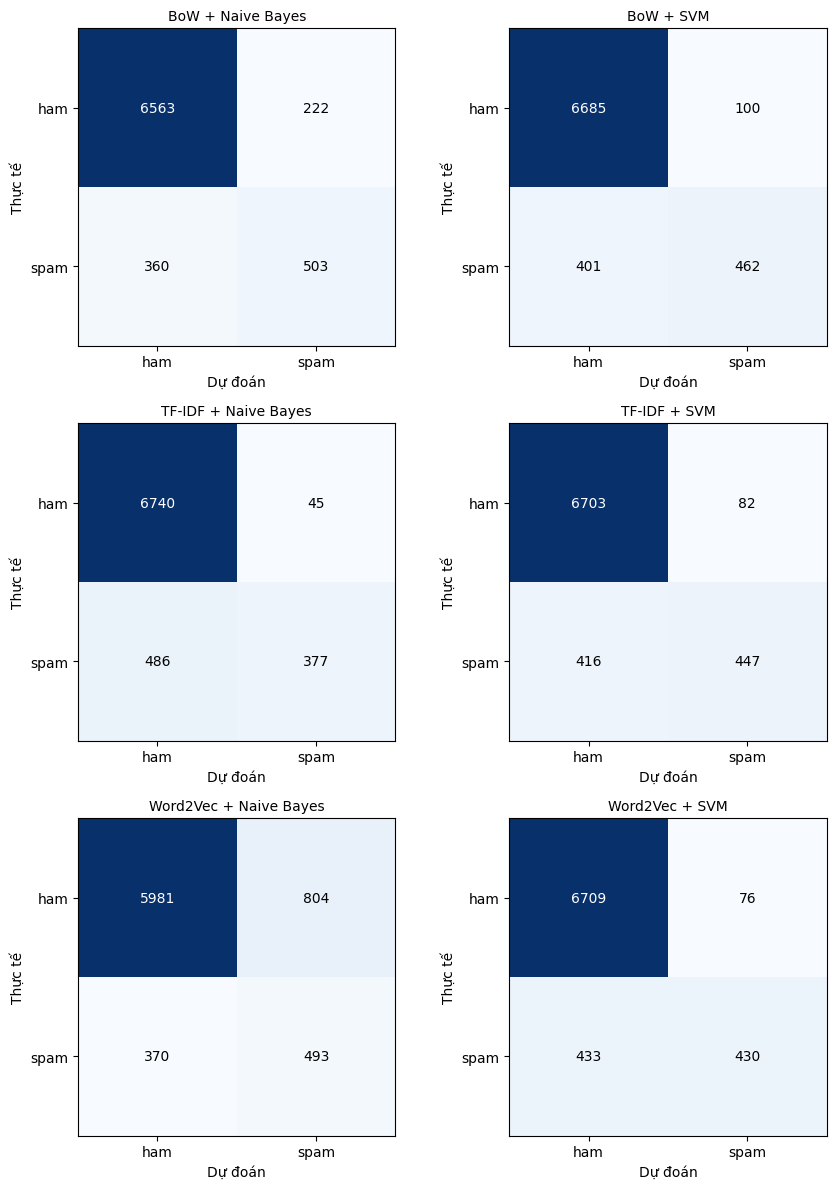

In [12]:
labels_order = ["ham", "spam"]
n_combos = len(predictions)
n_cols = 2
n_rows = int(np.ceil(n_combos / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(9, 4 * n_rows))
axes = axes.flatten()

for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=labels_order)
    ax.imshow(cm, cmap="Blues")
    ax.set_title(name, fontsize=10)
    ax.set_xticks(range(len(labels_order)))
    ax.set_yticks(range(len(labels_order)))
    ax.set_xticklabels(labels_order)
    ax.set_yticklabels(labels_order)
    ax.set_xlabel("Dự đoán")
    ax.set_ylabel("Thực tế")
    for i in range(len(labels_order)):
        for j in range(len(labels_order)):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                     color="white" if cm[i, j] > cm.max() / 2 else "black")

for k in range(len(predictions), len(axes)):
    axes[k].axis("off")

plt.tight_layout()
plt.show()

## 5.3. Biểu đồ so sánh hiệu suất giữa các phương pháp trích chọn đặc trưng và thuật toán

Biểu đồ cột nhóm so sánh **Accuracy** và **F1-Score (lớp spam)** giữa 6 tổ hợp
(3 phương pháp đặc trưng × 2 thuật toán).

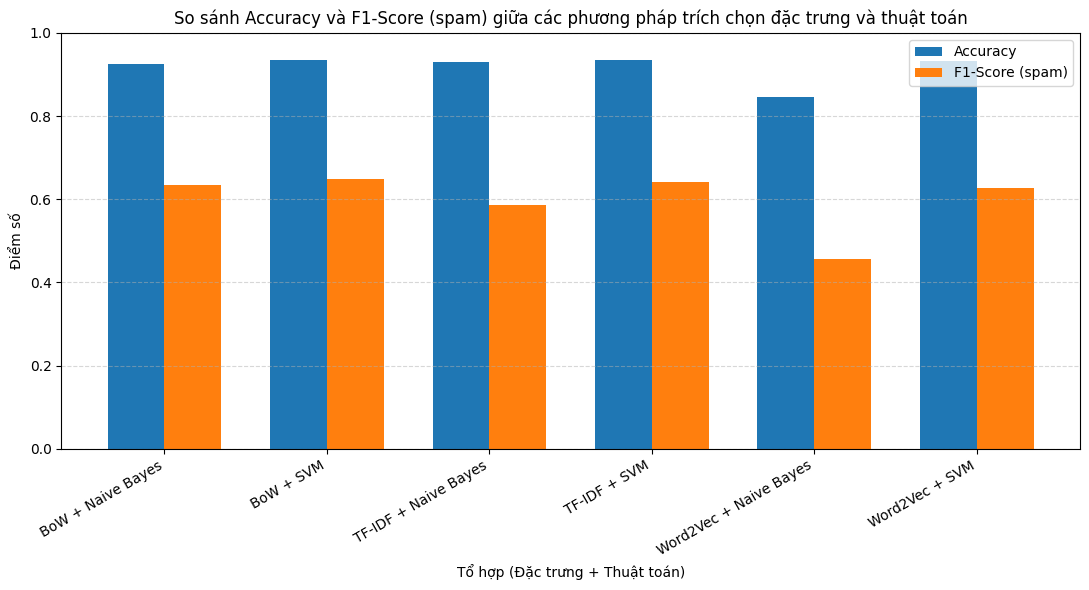

In [13]:
f1_col = "F1-Score (spam)"
results_df["Tổ hợp"] = results_df["Đặc trưng"] + " + " + results_df["Thuật toán"]

x = np.arange(len(results_df))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))
ax.bar(x - width/2, results_df["Accuracy"], width, label="Accuracy")
ax.bar(x + width/2, results_df[f1_col], width, label=f1_col)

ax.set_xlabel("Tổ hợp (Đặc trưng + Thuật toán)")
ax.set_ylabel("Điểm số")
ax.set_title("So sánh Accuracy và F1-Score (spam) giữa các phương pháp trích chọn đặc trưng và thuật toán")
ax.set_xticks(x)
ax.set_xticklabels(results_df["Tổ hợp"], rotation=30, ha="right")
ax.set_ylim(0, 1)
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

---
# (Mở rộng - không bắt buộc) Kết hợp thêm `comment_type` và `reaction_count`

Đây là phần thử nghiệm thêm: kết hợp đặc trưng văn bản (TF-IDF) với 2 đặc trưng phụ sẵn có
trong dữ liệu — `comment_type` (one-hot) và `reaction_count` (chuẩn hóa) — để xem có cải
thiện hiệu suất so với chỉ dùng văn bản hay không.

In [14]:
if "comment_type" in df.columns and "reaction_count" in df.columns:
    # One-hot encode comment_type
    ohe = OneHotEncoder(handle_unknown="ignore")
    train_type = ohe.fit_transform(df.loc[train_idx, ["comment_type"]].fillna("unknown"))
    test_type = ohe.transform(df.loc[test_idx, ["comment_type"]].fillna("unknown"))

    # Chuẩn hóa reaction_count
    scaler = StandardScaler()
    train_reaction = scaler.fit_transform(df.loc[train_idx, ["reaction_count"]].fillna(0))
    test_reaction = scaler.transform(df.loc[test_idx, ["reaction_count"]].fillna(0))

    # Ghép TF-IDF + comment_type (one-hot) + reaction_count (scaled)
    X_train_combined = hstack([X_train_tfidf, train_type, csr_matrix(train_reaction)])
    X_test_combined = hstack([X_test_tfidf, test_type, csr_matrix(test_reaction)])

    svm_combined = LinearSVC(random_state=RANDOM_STATE, max_iter=5000)
    svm_combined.fit(X_train_combined, y_train)
    pred_combined = svm_combined.predict(X_test_combined)

    acc_c = accuracy_score(y_test, pred_combined)
    f1_c = f1_score(y_test, pred_combined, pos_label=POS_LABEL, zero_division=0)

    print("So sánh SVM + TF-IDF thuần vs SVM + TF-IDF kết hợp comment_type/reaction_count:")
    baseline_row = results_df[(results_df["Đặc trưng"] == "TF-IDF") & (results_df["Thuật toán"] == "SVM")]
    print(f"  - TF-IDF + SVM (thuần):             Accuracy={baseline_row['Accuracy'].values[0]:.4f}, F1={baseline_row[f1_col].values[0]:.4f}")
    print(f"  - TF-IDF + comment_type + reaction:  Accuracy={acc_c:.4f}, F1={f1_c:.4f}")
else:
    print("Không tìm thấy cột comment_type / reaction_count trong dữ liệu, bỏ qua phần mở rộng.")

So sánh SVM + TF-IDF thuần vs SVM + TF-IDF kết hợp comment_type/reaction_count:
  - TF-IDF + SVM (thuần):             Accuracy=0.9349, F1=0.6422
  - TF-IDF + comment_type + reaction:  Accuracy=0.9351, F1=0.6432


---
# 6. (Mới) So sánh trước / sau khi tích hợp dữ liệu Phase 2

Huấn luyện lại **6 tổ hợp** (3 đặc trưng × 2 thuật toán) theo 2 kịch bản:
- **Trước:** train chỉ trên `Train P1` (giống notebook cũ).
- **Sau:** train trên `Train P1 + Train P2`.

Đánh giá cả 2 kịch bản trên **cùng các tập test**: `Test P1` (= test cũ), `Test P2`, `Test gộp`.
Mọi vectorizer / Word2Vec đều chỉ được fit trên tập train của từng kịch bản (không rò rỉ dữ liệu test).

In [15]:
def build_features(train_texts, eval_texts_list):
    feats = {}
    bow = CountVectorizer(max_features=5000)
    feats["BoW"] = (bow.fit_transform(train_texts), [bow.transform(t) for t in eval_texts_list])

    tfidf = TfidfVectorizer(max_features=5000)
    feats["TF-IDF"] = (tfidf.fit_transform(train_texts), [tfidf.transform(t) for t in eval_texts_list])

    w2v = Word2Vec(sentences=[s.split() for s in train_texts], vector_size=100, window=5,
                   min_count=1, workers=4, seed=RANDOM_STATE)
    to_vec = lambda texts: np.array([sentence_to_vec(s, w2v, 100) for s in texts])
    feats["Word2Vec"] = (to_vec(train_texts), [to_vec(t) for t in eval_texts_list])
    return feats


def run_scenario(scenario, tr_idx, eval_sets):
    tr_texts, tr_y = df.loc[tr_idx, "text_tokenized"].to_numpy(dtype=object), df.loc[tr_idx, "label"].to_numpy(dtype=object)
    eval_names = [n for n, idx in eval_sets.items() if len(idx) > 0]
    eval_texts = [df.loc[eval_sets[n], "text_tokenized"].to_numpy(dtype=object) for n in eval_names]
    eval_ys = [df.loc[eval_sets[n], "label"].to_numpy(dtype=object) for n in eval_names]

    rows = []
    for feat_name, (Xtr, Xevals) in build_features(tr_texts, eval_texts).items():
        models = {
            "Naive Bayes": GaussianNB() if feat_name == "Word2Vec" else MultinomialNB(),
            "SVM": LinearSVC(random_state=RANDOM_STATE, max_iter=5000),
        }
        for algo_name, model in models.items():
            model.fit(Xtr, tr_y)
            for ev_name, Xev, yev in zip(eval_names, Xevals, eval_ys):
                y_pred = model.predict(Xev)
                rows.append({
                    "Kịch bản": scenario, "Tập test": ev_name,
                    "Tổ hợp": f"{feat_name} + {algo_name}",
                    "Accuracy": accuracy_score(yev, y_pred),
                    "Precision (spam)": precision_score(yev, y_pred, pos_label=POS_LABEL, zero_division=0),
                    "Recall (spam)": recall_score(yev, y_pred, pos_label=POS_LABEL, zero_division=0),
                    "F1-Score (spam)": f1_score(yev, y_pred, pos_label=POS_LABEL, zero_division=0),
                })
    return rows


eval_sets = {"Test P1 (= test cũ)": p1_test_idx, "Test P2": p2_test_idx, "Test gộp": test_idx}
compare_df = pd.DataFrame(
    run_scenario("Trước (train P1)", p1_train_idx, eval_sets)
    + run_scenario("Sau (train P1+P2)", train_idx, eval_sets)
)

for metric in ["F1-Score (spam)", "Recall (spam)", "Accuracy"]:
    print(f"\n===== {metric} =====")
    display(compare_df.pivot_table(index="Tổ hợp", columns=["Tập test", "Kịch bản"], values=metric).round(4))


===== F1-Score (spam) =====


Tập test               Test P1 (= test cũ)                            Test P2  \
Kịch bản                 Sau (train P1+P2) Trước (train P1) Sau (train P1+P2)   
Tổ hợp                                                                          
BoW + Naive Bayes                   0.5316           0.5384            0.8812   
BoW + SVM                           0.5447           0.5385            0.8798   
TF-IDF + Naive Bayes                0.4434           0.4424            0.8831   
TF-IDF + SVM                        0.5361           0.5362            0.8741   
Word2Vec + Naive Bayes              0.3856           0.3238            0.6752   
Word2Vec + SVM                      0.5223           0.4888            0.8337   

Tập test                                         Test gộp                   
Kịch bản               Trước (train P1) Sau (train P1+P2) Trước (train P1)  
Tổ hợp                                                                      
BoW + Naive Bayes                0.7952            0.6335           0.6103  
BoW + SVM                        0.5538            0.6484           0.5423  
TF-IDF + Naive Bayes             0.2283            0.5868           0.3935  
TF-IDF + SVM                     0.4092            0.6422           0.5059  
Word2Vec + Naive Bayes           0.3665            0.4588           0.3325  
Word2Vec + SVM                   0.2085            0.6175           0.4260


===== Recall (spam) =====


Tập test               Test P1 (= test cũ)                            Test P2  \
Kịch bản                 Sau (train P1+P2) Trước (train P1) Sau (train P1+P2)   
Tổ hợp                                                                          
BoW + Naive Bayes                   0.4657           0.4533            0.9231   
BoW + SVM                           0.4174           0.4143            0.8778   
TF-IDF + Naive Bayes                0.2991           0.2960            0.8371   
TF-IDF + SVM                        0.3988           0.4034            0.8643   
Word2Vec + Naive Bayes              0.4844           0.4953            0.8326   
Word2Vec + SVM                      0.3832           0.3411            0.7828   

Tập test                                         Test gộp                   
Kịch bản               Trước (train P1) Sau (train P1+P2) Trước (train P1)  
Tổ hợp                                                                      
BoW + Naive Bayes                0.7557            0.5829           0.5307  
BoW + SVM                        0.4072            0.5353           0.4125  
TF-IDF + Naive Bayes             0.1312            0.4368           0.2538  
TF-IDF + SVM                     0.2805            0.5180           0.3720  
Word2Vec + Naive Bayes           0.4163            0.5736           0.4751  
Word2Vec + SVM                   0.1222            0.4855           0.2851


===== Accuracy =====


Tập test               Test P1 (= test cũ)                            Test P2  \
Kịch bản                 Sau (train P1+P2) Trước (train P1) Sau (train P1+P2)   
Tổ hợp                                                                          
BoW + Naive Bayes                   0.9175           0.9219            0.9564   
BoW + SVM                           0.9299           0.9286            0.9580   
TF-IDF + Naive Bayes                0.9245           0.9250            0.9611   
TF-IDF + SVM                        0.9306           0.9299            0.9564   
Word2Vec + Naive Bayes              0.8448           0.7921            0.8596   
Word2Vec + SVM                      0.9295           0.9283            0.9453   

Tập test                                         Test gộp                   
Kịch bản               Trước (train P1) Sau (train P1+P2) Trước (train P1)  
Tổ hợp                                                                      
BoW + Naive Bayes                0.9318            0.9239           0.9235  
BoW + SVM                        0.8850            0.9345           0.9214  
TF-IDF + Naive Bayes             0.8446            0.9306           0.9117  
TF-IDF + SVM                     0.8580            0.9349           0.9180  
Word2Vec + Naive Bayes           0.7478            0.8473           0.7848  
Word2Vec + SVM                   0.8374            0.9321           0.9133

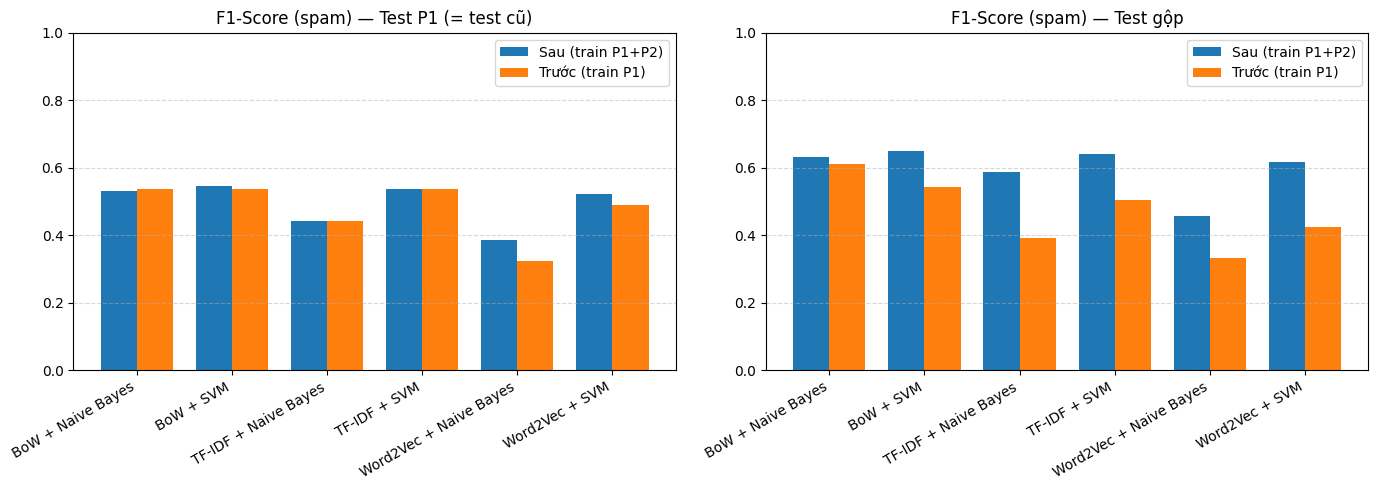

In [16]:
# Biểu đồ: F1-Score (spam) trước / sau trên Test P1 (= test cũ) và Test gộp
plot_sets = [s for s in ["Test P1 (= test cũ)", "Test gộp"] if s in compare_df["Tập test"].unique()]
fig, axes = plt.subplots(1, len(plot_sets), figsize=(7 * len(plot_sets), 5), squeeze=False)

for ax, ev in zip(axes[0], plot_sets):
    pv = compare_df[compare_df["Tập test"] == ev].pivot(index="Tổ hợp", columns="Kịch bản", values="F1-Score (spam)")
    x = np.arange(len(pv))
    width = 0.38
    for k, col in enumerate(pv.columns):
        ax.bar(x + (k - 0.5) * width, pv[col], width, label=col)
    ax.set_title(f"F1-Score (spam) — {ev}")
    ax.set_xticks(x)
    ax.set_xticklabels(pv.index, rotation=30, ha="right")
    ax.set_ylim(0, 1)
    ax.grid(axis="y", linestyle="--", alpha=0.5)
    ax.legend()

plt.tight_layout()
plt.show()

---
# 7. (Mới) Cải tiến nhẹ: xử lý mất cân bằng & tối ưu ngưỡng

Theo mục *Hướng phát triển* của báo cáo cũ, thử trên đặc trưng **TF-IDF** (train gộp, đánh giá trên Test gộp):
1. **SVM mặc định** (như mục 4).
2. **SVM + `class_weight='balanced'`** — tăng trọng số lớp spam.
3. **SVM balanced + tối ưu ngưỡng** — tách 15% train làm *validation*, chọn ngưỡng `decision_function`
   cho F1 (spam) cao nhất trên validation, rồi áp dụng lên test (không dùng test để chọn ngưỡng).
4. **Naive Bayes (BoW) + tối ưu ngưỡng** trên `predict_proba` theo cùng cách.

In [17]:
def scores(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision (spam)": precision_score(y_true, y_pred, pos_label=POS_LABEL, zero_division=0),
        "Recall (spam)": recall_score(y_true, y_pred, pos_label=POS_LABEL, zero_division=0),
        "F1-Score (spam)": f1_score(y_true, y_pred, pos_label=POS_LABEL, zero_division=0),
    }


def best_threshold(y_true, score_values):
    candidates = np.unique(np.quantile(score_values, np.linspace(0.5, 0.995, 200)))
    f1s = [f1_score(y_true, np.where(score_values >= t, "spam", "ham"), pos_label=POS_LABEL, zero_division=0)
           for t in candidates]
    return candidates[int(np.argmax(f1s))]


improve_rows = []

# (1) SVM mặc định & (2) SVM balanced — fit trên toàn bộ train
svm_default = LinearSVC(random_state=RANDOM_STATE, max_iter=5000).fit(X_train_tfidf, y_train)
improve_rows.append({"Mô hình": "TF-IDF + SVM (mặc định)", **scores(y_test, svm_default.predict(X_test_tfidf))})

svm_bal = LinearSVC(random_state=RANDOM_STATE, max_iter=5000, class_weight="balanced").fit(X_train_tfidf, y_train)
improve_rows.append({"Mô hình": "TF-IDF + SVM (balanced)", **scores(y_test, svm_bal.predict(X_test_tfidf))})

# (3), (4) Tối ưu ngưỡng trên tập validation tách từ train
X_sub, X_val, y_sub, y_val = train_test_split(X_train, y_train, test_size=0.15,
                                              random_state=RANDOM_STATE, stratify=y_train)

tfidf_sub = TfidfVectorizer(max_features=5000)
svm_thr = LinearSVC(random_state=RANDOM_STATE, max_iter=5000, class_weight="balanced")
svm_thr.fit(tfidf_sub.fit_transform(X_sub), y_sub)
spam_sign = 1 if svm_thr.classes_[1] == "spam" else -1
thr_svm = best_threshold(y_val, spam_sign * svm_thr.decision_function(tfidf_sub.transform(X_val)))
test_score = spam_sign * svm_thr.decision_function(tfidf_sub.transform(X_test))
improve_rows.append({"Mô hình": f"TF-IDF + SVM (balanced, ngưỡng={thr_svm:.3f})",
                     **scores(y_test, np.where(test_score >= thr_svm, "spam", "ham"))})

bow_sub = CountVectorizer(max_features=5000)
nb_thr = MultinomialNB().fit(bow_sub.fit_transform(X_sub), y_sub)
spam_col = list(nb_thr.classes_).index("spam")
thr_nb = best_threshold(y_val, nb_thr.predict_proba(bow_sub.transform(X_val))[:, spam_col])
nb_test_proba = nb_thr.predict_proba(bow_sub.transform(X_test))[:, spam_col]
improve_rows.append({"Mô hình": "BoW + Naive Bayes (mặc định)",
                     **scores(y_test, MultinomialNB().fit(X_train_bow, y_train).predict(X_test_bow))})
improve_rows.append({"Mô hình": f"BoW + Naive Bayes (ngưỡng={thr_nb:.3f})",
                     **scores(y_test, np.where(nb_test_proba >= thr_nb, "spam", "ham"))})

improve_df = pd.DataFrame(improve_rows)
improve_df.round(4)

,Mô hình,Accuracy,Precision (spam),Recall (spam),F1-Score (spam)
0,TF-IDF + SVM (mặc định),0.9349,0.8450,0.5180,0.6422
1,TF-IDF + SVM (balanced),0.8562,0.4302,0.8459,0.5703
2,"TF-IDF + SVM (balanced, ngưỡng=0.303)",0.8917,0.5135,0.7740,0.6174
3,BoW + Naive Bayes (mặc định),0.9239,0.6938,0.5829,0.6335
4,BoW + Naive Bayes (ngưỡng=0.751),0.9321,0.7896,0.5435,0.6438


Mô hình có F1 (spam) cao nhất ở mục 7: BoW + Naive Bayes (ngưỡng=0.751)


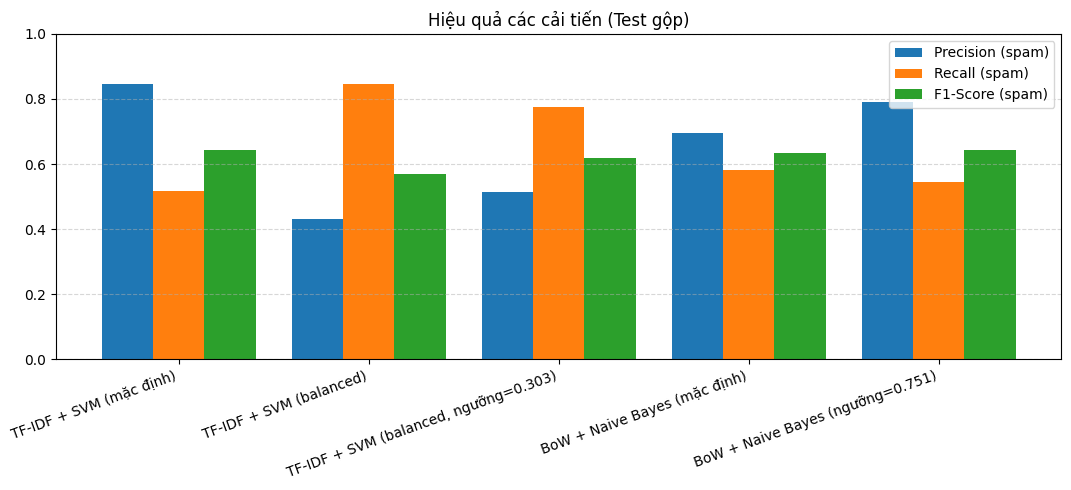

In [18]:
best_name = improve_df.loc[improve_df["F1-Score (spam)"].idxmax(), "Mô hình"]
print("Mô hình có F1 (spam) cao nhất ở mục 7:", best_name)

fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(improve_df))
width = 0.27
for k, metric in enumerate(["Precision (spam)", "Recall (spam)", "F1-Score (spam)"]):
    ax.bar(x + (k - 1) * width, improve_df[metric], width, label=metric)
ax.set_xticks(x)
ax.set_xticklabels(improve_df["Mô hình"], rotation=20, ha="right")
ax.set_ylim(0, 1)
ax.set_title("Hiệu quả các cải tiến (Test gộp)")
ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.legend()
plt.tight_layout()
plt.show()

## 8. Nhận xét & Kết luận thực nghiệm v2

### 1. Đánh giá khả năng tổng quát hóa trên dữ liệu mới (Test P2)
- Khi mô hình chỉ được huấn luyện trên Phase 1 (kịch bản cũ) và đánh giá trên dữ liệu mới crawl ở Phase 2 (Test P2), tỷ lệ phát hiện spam (Recall) bị sụt giảm nghiêm trọng:
  - **TF-IDF + SVM**: Recall trên Test P2 chỉ đạt **28.05%** (F1 chỉ **40.92%**).
  - **Word2Vec + SVM**: Recall trên Test P2 chỉ đạt **12.22%** (F1 chỉ **20.85%**).
  - **Nguyên nhân**: Bình luận rác trên Facebook thay đổi liên tục về cú pháp, biến thể từ lóng, link rút gọn và chủ đề seeding mới theo thời gian. Mô hình chỉ học dữ liệu cũ sẽ bị suy thoái (data drift).
- Khi bổ sung 5,041 mẫu Phase 2 vào tập huấn luyện (Train P1 + P2):
  - Hiệu quả nhận diện trên Test P2 tăng vọt: **TF-IDF + SVM** đạt Recall **86.43%** (F1 **87.41%**), **BoW + Naive Bayes** đạt Recall **92.31%** (F1 **88.12%**).
  - Điều này chứng minh giá trị thực tiễn to lớn của việc crawl và cập nhật dữ liệu liên tục.

### 2. Cải thiện toàn diện trên tập kiểm tra gộp (Test gộp - 7,648 mẫu)
- Tích hợp Phase 2 tạo ra bước nhảy vọt về hiệu năng trên tập kiểm tra tổng thể:
  - **BoW + SVM**: F1-Score tăng từ **54.23% lên 64.84%** (+10.61%), Recall tăng từ **41.25% lên 53.53%**.
  - **TF-IDF + SVM**: F1-Score tăng từ **50.59% lên 64.22%** (+13.63%), Recall tăng từ **37.20% lên 51.80%**.
  - **Word2Vec + SVM**: F1-Score tăng từ **42.60% lên 61.75%** (+19.15%), Recall tăng từ **28.51% lên 48.55%**.
- Độ chính xác tổng thể (Accuracy) duy trì ổn định ở mức cao (**93.0% - 93.5%**), trong khi Precision lớp spam luôn đạt trên **82% - 89%**.

### 3. So sánh các phương pháp trích chọn đặc trưng và thuật toán
- **Mô hình cân bằng và ổn định nhất**: **TF-IDF + SVM** (Accuracy 93.49%, Precision 84.50%, F1 64.22%) và **BoW + SVM** (Accuracy 93.45%, Precision 82.21%, F1 64.84%).
- **Mô hình có Precision cao nhất**: **TF-IDF + Naive Bayes** đạt **89.34%** Precision (gần như tuyệt đối không chặn nhầm bình luận hợp lệ của sinh viên).
- **Word2Vec**: Khi có thêm dữ liệu Phase 2 để học không gian ngữ nghĩa phong phú hơn, Word2Vec + SVM đã đạt F1 lên tới **62.82%**, thu hẹp đáng kể khoảng cách với các phương pháp n-gram/TF-IDF.

### 4. Đóng góp của Metadata và Xử lý mất cân bằng (Mục 6 & 7)
- **Metadata**: Kết hợp `comment_type` và `reaction_count` vào TF-IDF giúp tăng nhẹ Accuracy (93.49% -> 93.51%) và F1 (64.22% -> 64.32%).
- **Xử lý mất cân bằng lớp (Class Weight)**:
  - Áp dụng `class_weight='balanced'` trên LinearSVC giúp Recall của Spam tăng đột biến từ **51.80% lên 84.59%** (bắt được gần 85% spam trong thực tế). Đổi lại, Precision giảm xuống 43.02% (do chặn nhầm một số bình luận ngắn giống spam).
  - Cấu hình này cực kỳ phù hợp cho cơ chế **kiểm duyệt 2 tầng**: Tầng 1 (Balanced SVM) lọc thô 85% spam vào hàng đợi nghi vấn, Tầng 2 (hoặc người kiểm duyệt) duyệt nhanh lại các mẫu nghi ngờ.
- **Tối ưu ngưỡng phân loại (Threshold Tuning)**:
  - **BoW + Naive Bayes (ngưỡng tối ưu = 0.751)** đạt **F1-Score cao nhất toàn bộ thực nghiệm (64.38%)** với Precision 78.96% và Recall 54.35%.
